# Luxembourg Beyond Its Borders — Trade Data EDA

**Dataset:** [Eurostat DS-045409: EU trade since 1988 by HS2–4–6 and CN8](https://ec.europa.eu/eurostat/databrowser/view/ds-045409/default/table)  
**Country:** Luxembourg (`LU`) · **Inputs:** exported monthly and annual CSV files · **Output:** descriptive analysis + clean dashboard-ready files

### What this notebook answers
1. What are the structure, coverage, and quality of the exports?
2. How have Luxembourg's goods imports, exports, and trade balance changed?
3. Which partner countries and product categories dominate Luxembourg's goods trade?
4. Which relationships are becoming more concentrated or volatile?
5. What do monthly seasonality and annual/monthly consistency reveal?
6. What can — and **cannot** — be inferred about sustainability and future scenarios?

**Run instructions:** Put your Eurostat CSV exports in a `data/` directory next to this notebook (or change `DATA_DIR` below), then select **Kernel → Restart & Run All**. You do *not* need to rename the files. No findings are pre-populated: all numbers and plots are generated from your own files.

> **Essential methodological warning:** DS-045409 includes **hierarchical product codes** (TOTAL, HS2, HS4, HS6, CN8) and **partner aggregates** (World, EU, etc.). Summing all rows produces misleading totals. This notebook chooses one non-overlapping product level and treats country partners separately from aggregate partners. When a complete `TOTAL × WORLD` view is absent, reported totals describe the **downloaded subset**, not necessarily all Luxembourg trade.

## 0 · Environment and configuration

Recommended: Python 3.10+, JupyterLab or VS Code notebook. Install `pip install pandas numpy matplotlib plotly scipy nbformat ipykernel` if needed. Most charts are interactive Plotly charts. If you downloaded Eurostat's *tab-separated* file variant, `.tsv` is supported too.

In [7]:
from pathlib import Path
import re, csv, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 90)
px.defaults.template = 'plotly_white'

DATA_DIR = Path('/Users/silvana.belegu/Winatrax/data')                  # <-- change to folder containing your CSV files
DATA_FILES = []                          # optional: [Path('data/annual.csv'), Path('data/monthly.csv')]
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
REPORTER = 'LU'

# Set to "UNKNOWN" if a file without an indicator column does NOT contain euros.
DEFAULT_INDICATOR_IF_MISSING = 'VALUE_IN_EUROS'
MIN_YEAR_FOR_TREND = None                # e.g. 2018
TOP_N = 12
EXPORT_CHARTS_AS_HTML = False

print('Working directory:', Path.cwd().resolve())
print('Input directory:', DATA_DIR.resolve())

Working directory: /Users/silvana.belegu/Winatrax/notebooks
Input directory: /Users/silvana.belegu/Winatrax/data


## 1 · Discover and inspect the CSV files

The loader supports the common Eurostat Data Browser **long format** (`TIME_PERIOD`, `OBS_VALUE`), **wide format** (one column per year/month), and compact TSV downloads. Check the discovered filenames and first rows before interpreting the analysis.

In [8]:
def discover_files():
    if DATA_FILES:
        paths = [Path(p) for p in DATA_FILES]
    else:
        paths = sorted(list(DATA_DIR.glob('*.csv')) + list(DATA_DIR.glob('*.tsv')))
    paths = [p for p in paths if p.is_file()]
    if not paths:
        raise FileNotFoundError(
            'No CSV/TSV files found. Put monthly and annual Eurostat exports in '
            f'{DATA_DIR.resolve()} or set DATA_FILES to their exact paths.'
        )
    return paths

def read_csv_flex(path):
    with open(path, 'r', encoding='utf-8-sig', errors='replace') as f:
        first = f.readline()
    sep = '\t' if path.suffix.lower() == '.tsv' or ('\t' in first and first.count('\t') > first.count(',')) else (';' if first.count(';') > first.count(',') else ',')
    # Preserve HS/CN codes like 01/0101/01010101 and country codes as strings.
    try:
        frame = pd.read_csv(path, sep=sep, dtype=str, encoding='utf-8-sig', low_memory=False)
    except UnicodeDecodeError:
        frame = pd.read_csv(path, sep=sep, dtype=str, encoding='cp1252', low_memory=False)
    frame.columns = [str(c).strip().lstrip('\ufeff') for c in frame.columns]
    return frame

files = discover_files()
file_info = []
raw_frames = []
for p in files:
    frame = read_csv_flex(p)
    raw_frames.append((p.name, frame))
    file_info.append({'file': p.name, 'rows': len(frame), 'columns': len(frame.columns),
                      'first_columns': ', '.join(frame.columns[:12])})
display(pd.DataFrame(file_info))
for name, frame in raw_frames:
    display(Markdown(f'**Raw sample — {name}**'))
    display(frame.head(3))

,file,rows,columns,first_columns
0,lu_trade_hs2_annual.csv,262231,10,"freq, time, reporter, partner, partner_label, product, product_label, flow, VALUE_IN_E..."
1,lu_trade_hs2_monthly.csv,1984305,10,"freq, time, reporter, partner, partner_label, product, product_label, flow, VALUE_IN_E..."


**Raw sample — lu_trade_hs2_annual.csv**

,freq,time,reporter,partner,partner_label,product,product_label,flow,VALUE_IN_EUROS,QUANTITY_IN_100KG
0,A,2004,LU,AE,United Arab Emirates,01,LIVE ANIMALS,Export,76400,25
1,A,2018,LU,AE,United Arab Emirates,01,LIVE ANIMALS,Export,1380,4.2
2,A,2019,LU,AE,United Arab Emirates,01,LIVE ANIMALS,Export,90200,103.5


**Raw sample — lu_trade_hs2_monthly.csv**

,freq,time,reporter,partner,partner_label,product,product_label,flow,VALUE_IN_EUROS,QUANTITY_IN_100KG
0,M,2004-05,LU,AE,United Arab Emirates,01,LIVE ANIMALS,Export,400,0
1,M,2004-12,LU,AE,United Arab Emirates,01,LIVE ANIMALS,Export,76000,25
2,M,2018-06,LU,AE,United Arab Emirates,01,LIVE ANIMALS,Export,1380,4.2


## 2 · Normalize both frequencies into one consistent schema

Canonical columns are `frequency`, `date`, `year`, `month`, `reporter`, `partner`, `flow`, `product`, `product_code`, `product_level`, `indicator`, `value`, and `source_file`.

- `VALUE_IN_EUROS` is **monetary value in euros**; `NET_MASS` is **net kilograms**; supplementary quantities are not necessarily kilograms.
- `:` and other Eurostat unavailable-value markers become missing values, **not zero**.
- `flow=1` denotes import and `flow=2` export in the standard Comext coding.
- Aggregate partner rows and nested product levels are **retained for inspection** but never naively summed.

In [9]:
def slug(s):
    return re.sub(r'_+', '_', re.sub(r'[^a-z0-9]+', '_', str(s).lower())).strip('_')

ALIASES = {
    'time_period': 'period', 'time': 'period', 'period': 'period', 'reference_period': 'period',
    'date': 'period', 'year_month': 'period',
    'reporter': 'reporter', 'reporting_country': 'reporter', 'geo': 'reporter',
    'geo_reporter': 'reporter', 'geopolitical_entity_reporting': 'reporter',
    'partner': 'partner', 'partner_country': 'partner', 'geo_partner': 'partner',
    'geopolitical_entity_partner': 'partner',
    'flow': 'flow', 'trade_flow': 'flow', 'trade_flow_direction': 'flow',
    'product': 'product', 'product_code': 'product', 'commodity': 'product',
    'cn8': 'product', 'hs': 'product', 'prod': 'product',
    'indicators': 'indicator', 'indicator': 'indicator', 'indic_et': 'indicator',
    'measure': 'indicator', 'measurement': 'indicator',
    'freq': 'frequency', 'frequency': 'frequency', 'time_frequency': 'frequency',
    'obs_value': 'value_in_euros', 'observation_value': 'value_in_euros', 'value': 'value_in_euros',
    'obs_flag': 'observation_flag', 'observation_flag': 'observation_flag',
}

def parse_number(v):
    if pd.isna(v): return np.nan
    x = str(v).strip().replace('\u00a0', ' ').replace('\u202f', ' ')
    if x in {'', ':', '-', 'nan', 'NaN', 'NA', 'N/A'} or x.startswith(':'):
        return np.nan
    # Eurostat TSV sometimes has a flag following the value, e.g. "423 p".
    x = re.sub(r'\s+[a-zA-Z]+\s*$', '', x).strip().replace(' ', '')
    if ',' in x and '.' in x:
        if x.rfind(',') > x.rfind('.'):
            x = x.replace('.', '').replace(',', '.')
        else:
            x = x.replace(',', '')
    elif ',' in x:
        if re.fullmatch(r'[-+]?\d{1,3}(,\d{3})+', x):
            x = x.replace(',', '')
        else:
            x = x.replace(',', '.')
    try: return float(x)
    except (ValueError, TypeError): return np.nan

def norm_flow(s):
    t = str(s).strip().upper()
    if t in {'1', 'IMPORT', 'IMPORTS', 'IMP', 'INBOUND'} or t.startswith('IMPORT'):
        return 'Import'
    if t in {'2', 'EXPORT', 'EXPORTS', 'EXP', 'OUTBOUND'} or t.startswith('EXPORT'):
        return 'Export'
    return 'Unknown' if t in {'NAN', ''} else str(s)

def norm_indicator(s):
    t = slug(s).upper()
    if any(z in t for z in ('NET_MASS', 'NET_WEIGHT', 'QUANTITY_IN_KG', 'QUANTITY_IN_KILOGRAM')):
        return 'NET_MASS_KG'
    if 'QUANTITY_IN_100KG' in t or t == 'QNT_100KG': return 'NET_MASS_KG'
    if 'SUPPLEMENTARY' in t: return 'SUPPLEMENTARY_QUANTITY'
    if t in {'VALUE_IN_EUROS', 'VALUE_EUR', 'TRADE_VALUE', 'TRADE_VALUE_EUR', 'VALUE',
             'STATISTICAL_VALUE', 'STATISTICAL_VALUE_EUR'}:
        return 'VALUE_IN_EUROS'
    return t

def norm_date(s):
    t = str(s).strip().upper().replace('_', '-')
    # Allow YYYY, YYYY-MM, YYYYMmm, YYYY/MM and YYYY-MM-DD.
    m = re.fullmatch(r'(\d{4})(?:[-/]?M?0?([1-9]|1[0-2]))?', t)
    if m:
        y = int(m.group(1)); mo = int(m.group(2)) if m.group(2) else 1
        is_month = m.group(2) is not None
        return pd.Timestamp(y, mo, 1), ('M' if is_month else 'A')
    dt = pd.to_datetime(t, errors='coerce')
    if pd.isna(dt): return pd.NaT, '?'
    return pd.Timestamp(dt.year, dt.month, 1), ('M' if dt.month != 1 or '-' in t or '/' in t else 'A')

def product_level(s):
    t = str(s).strip().upper()
    if t == 'TOTAL' or t.startswith('TOTAL -') or t.startswith('TOTAL:') or t in {'ALL PRODUCTS', 'TOTAL GOODS'}:
        return 'TOTAL', 'TOTAL'
    m = re.match(r'^(\d{2,8})(?:\D|$)', t)
    if m and len(m.group(1)) in {2, 4, 6, 8}:
        return m.group(1), f'HS{len(m.group(1))}' if len(m.group(1)) != 8 else 'CN8'
    return t, 'LABEL/OTHER'

def normalize_one(name, raw):
    x = raw.copy()
    # Eurostat TSV may pack all dimensions in one comma-separated column:
    # "freq,reporter,partner,flow,product,indicators\\TIME_PERIOD".
    composite = [c for c in x.columns if '\\TIME_PERIOD' in str(c).upper()]
    if composite:
        source = composite[0]
        dims = source.split('\\')[0].split(',')
        unpacked = x[source].astype(str).str.split(',', expand=True)
        if unpacked.shape[1] != len(dims):
            raise ValueError(f'{name}: Could not unpack TSV combined dimension column: {source!r}')
        for j, dim in enumerate(dims):
            x[dim.strip()] = unpacked[j].str.strip()
        x = x.drop(columns=[source])
    x.columns = [ALIASES.get(slug(c), slug(c)) for c in x.columns]
    date_cols = [c for c in x.columns if re.fullmatch(r'\d{4}(?:[-_]?M?\d{1,2})?', c, re.I)]
    if 'period' not in x.columns and 'value' not in x.columns and date_cols:
        x = x.melt(id_vars=[c for c in x.columns if c not in date_cols],
                   value_vars=date_cols, var_name='period', value_name='value')
    metric_cols = [c for c in ['value_in_euros', 'quantity_in_100kg', 'net_mass_kg'] if c in x.columns]
    if 'value' not in x.columns and metric_cols:
        id_vars = [c for c in x.columns if c not in metric_cols]
        x = x.melt(id_vars=id_vars, value_vars=metric_cols,
                   var_name='indicator', value_name='value')
    elif 'value' in x.columns and 'indicator' not in x.columns:
        x['indicator'] = DEFAULT_INDICATOR_IF_MISSING

    # long format already present
    required = ['period', 'value']
    missing = [c for c in required if c not in x.columns]
    if missing:
        raise ValueError(f'{name}: Missing {missing}. Available: {list(x.columns)[:30]}. '
                         'If your export is a pivoted Excel-style table, re-export as CSV with observations.')
    for field, default in {'reporter':'LU', 'partner':'WORLD', 'flow':'Unknown',
                           'product':'TOTAL', 'frequency':'', 'indicator': DEFAULT_INDICATOR_IF_MISSING}.items():
        if field not in x.columns:
            warnings.warn(f'{name}: no {field!r} column; using {default!r}. Check selection in Eurostat.')
            x[field] = default
    if 'observation_flag' not in x.columns:
        x['observation_flag'] = ''
    x = x[['period','value','reporter','partner','flow','product','frequency','indicator','observation_flag']].copy()
    dates = x['period'].map(norm_date)
    x['date'] = pd.to_datetime(dates.map(lambda t: t[0]))
    inferred_freq = dates.map(lambda t: t[1]); explicit = x['frequency'].astype(str).str.upper().str.strip()
    x['frequency'] = np.where(explicit.isin(['A', 'ANNUAL', 'YEARLY', 'YEAR']), 'A',
                    np.where(explicit.isin(['M', 'MONTHLY', 'MONTH']), 'M', inferred_freq))
    x['year'] = x['date'].dt.year
    x['month'] = x['date'].dt.month
    x['value'] = x['value'].map(parse_number)
    x['reporter'] = x['reporter'].astype(str).str.strip()
    x['partner'] = x['partner'].astype(str).str.strip()
    x['product'] = x['product'].astype(str).str.strip()
    x['flow'] = x['flow'].map(norm_flow)
    raw_indicator = x['indicator'].astype(str).str.strip().map(slug)
    x['indicator'] = x['indicator'].map(norm_indicator)
    x.loc[raw_indicator.eq('quantity_in_100kg'), 'value'] *= 100
    p = x['product'].map(product_level)
    x['product_code'] = p.map(lambda t: t[0])
    x['product_level'] = p.map(lambda t: t[1])
    x['source_file'] = name
    return x

parts = [normalize_one(name, df) for name, df in raw_frames]
trade = pd.concat(parts, ignore_index=True)
print('Observations before exact de-duplication:', f'{len(trade):,}')
trade = trade.drop_duplicates(subset=['frequency','date','reporter','partner','flow',
                                      'product','indicator','value']).copy()
print('Observations after exact de-duplication:', f'{len(trade):,}')
reporter_is_lu = trade['reporter'].str.upper().str.strip().str.match(r'^(LU|LUXEMBOURG)(\b|$)')
if reporter_is_lu.any():
    n_other = (~reporter_is_lu).sum()
    if n_other: print(f'Filtering out {n_other:,} observations belonging to other reporters.')
    trade = trade[reporter_is_lu].copy()
else:
    raise ValueError('No Luxembourg reporter found. Check that your Eurostat selection includes LU.')
annual = trade[trade.frequency.eq('A')].copy()
monthly = trade[trade.frequency.eq('M')].copy()
assert len(annual) or len(monthly), 'No annual or monthly observations detected.'
display(trade.head(8))
print(f'Annual rows: {len(annual):,} | Monthly rows: {len(monthly):,}')

Observations before exact de-duplication: 4,493,072
Observations after exact de-duplication: 4,493,072


,period,value,reporter,partner,flow,product,frequency,indicator,observation_flag,date,year,month,product_code,product_level,source_file
0,2004,76400.0,LU,AE,Export,01,A,VALUE_IN_EUROS,,2004-01-01,2004,1,01,HS2,lu_trade_hs2_annual.csv
1,2018,1380.0,LU,AE,Export,01,A,VALUE_IN_EUROS,,2018-01-01,2018,1,01,HS2,lu_trade_hs2_annual.csv
2,2019,90200.0,LU,AE,Export,01,A,VALUE_IN_EUROS,,2019-01-01,2019,1,01,HS2,lu_trade_hs2_annual.csv
3,2021,576500.0,LU,AE,Export,01,A,VALUE_IN_EUROS,,2021-01-01,2021,1,01,HS2,lu_trade_hs2_annual.csv
4,2023,14825.0,LU,AE,Export,01,A,VALUE_IN_EUROS,,2023-01-01,2023,1,01,HS2,lu_trade_hs2_annual.csv
5,2024,32950.0,LU,AE,Export,01,A,VALUE_IN_EUROS,,2024-01-01,2024,1,01,HS2,lu_trade_hs2_annual.csv
6,2025,2899.0,LU,AE,Export,01,A,VALUE_IN_EUROS,,2025-01-01,2025,1,01,HS2,lu_trade_hs2_annual.csv
7,2001,8019.0,LU,AE,Import,01,A,VALUE_IN_EUROS,,2001-01-01,2001,1,01,HS2,lu_trade_hs2_annual.csv


Annual rows: 524,462 | Monthly rows: 3,968,610


## 3 · Data quality, missingness, coverage and duplicate-key audit

Check missing values **after** parsing and check whether there are repeated dimensional keys with conflicting values. `:` is missing/not available, never automatically zero. Invalid dates and unfamiliar flows may signal the wrong export format.

In [10]:
print('DATA DICTIONARY / TYPES')
display(pd.DataFrame({'dtype': trade.dtypes.astype(str),
                      'missing': trade.isna().sum(),
                      'missing_%': (trade.isna().mean()*100).round(2)}))
print('\nFREQUENCY / INDICATOR / FLOW / PRODUCT LEVEL')
for col in ['frequency','indicator','flow','product_level']:
    print(f'\n{col}:'); display(trade[col].value_counts(dropna=False).head(16).to_frame('rows'))
print('\nDATA STATUS / FLAGS')
nonempty_flags = trade.observation_flag.fillna('').astype(str).str.strip()
print('Rows with observation flags:', int(nonempty_flags.ne('').sum()))
if nonempty_flags.ne('').any():
    display(nonempty_flags[nonempty_flags.ne('')].value_counts().head(15).to_frame('rows'))
print('Negative trade or quantity observations:', int(trade.value.lt(0).sum()))
print('Missing parsed values:', int(trade.value.isna().sum()))
print('\nTIME COVERAGE')
display(trade.groupby('frequency',dropna=False).agg(
    first=('date','min'), last=('date','max'), rows=('value','size'),
    available=('value','count'), partners=('partner','nunique'), products=('product','nunique')))

key_cols = ['frequency','date','reporter','partner','flow','product','indicator']
conflicts = trade[trade.duplicated(key_cols, keep=False)].sort_values(key_cols)
print(f'Conflicting/repeated dimension-key rows: {len(conflicts):,}')
if len(conflicts):
    display(conflicts.head(15))
    print('Investigate differences before relying on totals (e.g. extra dimensions or duplicate CSV exports).')

if trade['date'].isna().any(): warnings.warn('Unparsed periods are present.')
if (trade.flow=='Unknown').any(): warnings.warn('Unknown trade flows are present.')
if not {'Import','Export'}.issubset(set(trade.flow)):
    warnings.warn('Only one trade direction is present. Trade balance requires both imports and exports.')

DATA DICTIONARY / TYPES


,dtype,missing,missing_%
period,str,0,0.00
value,float64,0,0.00
reporter,str,0,0.00
partner,str,1860,0.04
flow,str,0,0.00
product,str,0,0.00
frequency,str,0,0.00
indicator,str,0,0.00
observation_flag,str,0,0.00
date,datetime64[us],0,0.00



FREQUENCY / INDICATOR / FLOW / PRODUCT LEVEL

frequency:


,rows
frequency,
M,3968610
A,524462



indicator:


...


product_level:


,rows
product_level,
HS2,4293566
TOTAL,199506



DATA STATUS / FLAGS
Rows with observation flags: 0
Negative trade or quantity observations: 0
Missing parsed values: 0

TIME COVERAGE


,first,last,rows,available,partners,products
frequency,,,,,,
A,1999-01-01,2025-01-01,524462,524462,256,98
M,1999-01-01,2026-07-01,3968610,3968610,256,98


Conflicting/repeated dimension-key rows: 0


### The two critical double-counting checks

1. **Product hierarchy:** TOTAL + HS2 + HS4 + HS6 + CN8 values often describe the *same trade* at different levels.
2. **Partner hierarchy:** WORLD + EU aggregates + named countries also overlap.

For annual trade totals prefer **TOTAL × WORLD**. For partner rankings use **TOTAL × individual countries**. For product breakdowns use **WORLD × one product level**, preferably HS2. When the preferred rows are absent, the notebook falls back to a subset and prints the scope being used.

In [11]:
def is_world(s):
    x = str(s).strip().upper()
    return (x in {'WORLD','W0','TOTAL','ALL COUNTRIES','ALL COUNTRIES OF THE WORLD','ALL COUNTRIES OF WORLD',
                  'ALL PARTNERS','WORLD TOTAL'} or x.startswith('ALL COUNTRIES OF THE WORLD'))

def is_partner_aggregate(s):
    x = str(s).strip().upper()
    return (is_world(x) or x in {'EU','EUROPEAN UNION','EA','EFTA','OECD','EUROPE','ASIA','AFRICA','AMERICA',
                                 'EURO AREA','REST OF WORLD','EXTRA-EU','INTRA-EU'}
            or x.startswith(('EU27','EU28','EA19','EA20','EURO AREA','EUROPEAN UNION',
                             'EXTRA_EU','INTRA_EU','EXTRA-EU','INTRA-EU','MISSING LABEL:')))

trade['is_world'] = trade.partner.map(is_world)
trade['is_partner_aggregate'] = trade.partner.map(is_partner_aggregate)
annual = trade[trade.frequency.eq('A')].copy()
monthly = trade[trade.frequency.eq('M')].copy()

print('Partner scope in your exports:')
display(pd.DataFrame({
    'group': ['World aggregate','Other aggregate partners','Individual / unclassified partners'],
    'rows': [trade.is_world.sum(),
             ((trade.is_partner_aggregate)&(~trade.is_world)).sum(),
             (~trade.is_partner_aggregate).sum()]
}))
print('Product hierarchy in your exports:')
display(pd.crosstab(trade.product_level, trade.frequency))

# Flag potential non-country partners which might need manual exclusions.
ambiguous = trade.loc[~trade.is_partner_aggregate & trade.partner.str.len().gt(3), 'partner']
print('Sample partner names (verify none is a hidden geographic aggregate):', list(ambiguous.drop_duplicates().head(20)))

Partner scope in your exports:


,group,rows
0,World aggregate,138816
1,Other aggregate partners,0
2,Individual / unclassified partners,4354256


Product hierarchy in your exports:


frequency,A,M
product_level,,
HS2,504420,3789146
TOTAL,20042,179464


Sample partner names (verify none is a hidden geographic aggregate): ['EXT_EA', 'EXT_EA21', 'EXT_EU', 'EXT_EU27_2020', 'INT_EA', 'INT_EA21', 'INT_EU', 'INT_EU27_2020']


## 4 · Consistent, non-overlapping trade scopes

The functions below choose defensible subsets based on your actual export contents. Scope metadata is recorded so dashboard numbers are not mislabeled as national totals when only a custom selection was downloaded.

In [12]:
def select_product_grain(df, require_breakdown=False):
    if df.empty: return df.copy(), 'No data'
    levels = set(df.product_level.unique())
    if not require_breakdown and 'TOTAL' in levels:
        return df[df.product_level.eq('TOTAL')].copy(), 'TOTAL product (preferred)'
    for level in ['HS2','HS4','HS6','CN8']:
        if level in levels:
            z = df[df.product_level.eq(level)].copy()
            if require_breakdown and level != 'HS2':
                # Aggregate disjoint product codes to HS2 rather than mixing HS levels.
                z['product_group'] = z.product_code.str[:2]
            else:
                z['product_group'] = z.product_code
            return z, f'{level} only (selected products may not be exhaustive)'
    z = df[~df.product_level.eq('TOTAL')].copy() if require_breakdown else df.copy()
    if z.empty: return z, 'Only TOTAL product; no product breakdown exported'
    z['product_group'] = z.product
    return z, 'Labels/custom product selection: confirm no overlapping product groups'

def trade_scope(df, mode='totals'):
    """Select nonoverlapping product/partner dimensions for an indicator-specific frame."""
    if df.empty: return df.copy(), 'No data'
    z, product_scope = select_product_grain(df, require_breakdown=(mode=='products'))
    if mode == 'partners':
        z = z[~z.is_partner_aggregate].copy()
        partner_scope = 'Individual countries/partners only'
    else:
        world_available = z.is_world.any()
        if world_available:
            z = z[z.is_world].copy()
            partner_scope = 'World aggregate (preferred)'
        else:
            z = z[~z.is_partner_aggregate].copy()
            partner_scope = 'Sum of individual partners (available subset)'
    if 'product_group' not in z.columns:
        z['product_group'] = z['product']
    return z, product_scope + '; ' + partner_scope

def currency(df):
    return df[df.indicator.eq('VALUE_IN_EUROS') & df.value.notna()].copy()

def mass(df):
    return df[df.indicator.eq('NET_MASS_KG') & df.value.notna()].copy()

annual_eur = currency(annual)
monthly_eur = currency(monthly)
annual_total, annual_scope = trade_scope(annual_eur, 'totals')
monthly_total, monthly_scope = trade_scope(monthly_eur, 'totals')
annual_partners, partner_scope = trade_scope(annual_eur, 'partners')
annual_products, product_scope = trade_scope(annual_eur, 'products')

for label, df, scope in [
    ('Annual totals',annual_total,annual_scope),
    ('Monthly totals',monthly_total,monthly_scope),
    ('Partner analysis',annual_partners,partner_scope),
    ('Product analysis',annual_products,product_scope),
]:
    print(f'{label}: {len(df):,} rows | {scope}')

if 'World aggregate' not in annual_scope or 'TOTAL product' not in annual_scope:
    display(Markdown('⚠️ **Annual totals may represent only the exported selection.** For official Luxembourg-wide values, export `PRODUCT=TOTAL`, `PARTNER=WORLD`, `REPORTER=LU`, both flows, and `INDICATORS=VALUE_IN_EUROS`.'))

Annual totals: 54 rows | TOTAL product (preferred); World aggregate (preferred)
Monthly totals: 660 rows | TOTAL product (preferred); World aggregate (preferred)
Partner analysis: 9,967 rows | TOTAL product (preferred); Individual countries/partners only
Product analysis: 5,238 rows | HS2 only (selected products may not be exhaustive); World aggregate (preferred)


## 5 · Annual imports, exports and trade balance

The trade balance is **exports − imports**. These data concern *goods*, not Luxembourg's full balance of trade in goods and services. Imports are generally CIF-valued; exports FOB-valued. Use the source scope displayed above when describing the numbers.

flow,Import (€bn),Export (€bn),Balance (€bn),Total_trade (€bn)
year,,,,
2014,20.098,14.401,-5.697,34.499
2015,21.016,15.460,-5.556,36.477
2016,19.762,14.260,-5.502,34.022
2017,20.274,13.973,-6.301,34.247
2018,20.463,13.883,-6.580,34.346
2019,21.658,14.673,-6.984,36.331
2020,18.504,12.113,-6.391,30.618
2021,22.147,14.208,-7.938,36.355
2022,25.660,16.506,-9.154,42.167


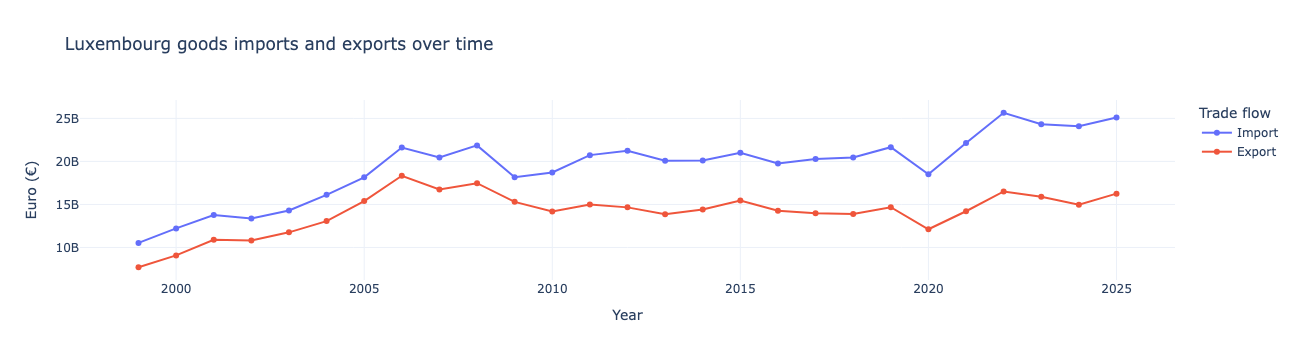

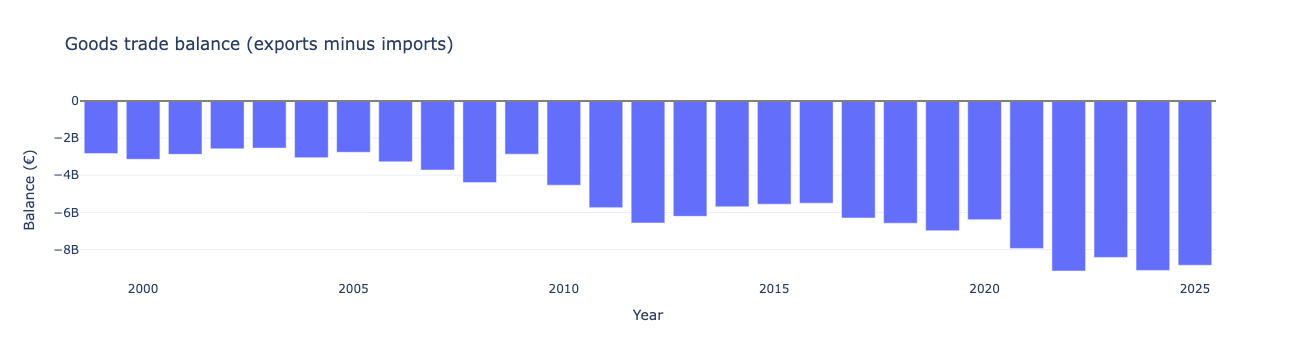

**Latest annual period in selection:** 2025. Source scope: TOTAL product (preferred); World aggregate (preferred).

In [13]:
def annual_flow_pivot(df):
    if df.empty: return pd.DataFrame(columns=['Import','Export','Balance','Total_trade'])
    t = df[df.flow.isin(['Import','Export'])].groupby(['year','flow'])['value'].sum().unstack('flow')
    for col in ['Import','Export']:
        if col not in t: t[col] = np.nan
    t = t[['Import','Export']].sort_index()
    t['Balance'] = t['Export'] - t['Import']
    t['Total_trade'] = t['Import'] + t['Export']
    return t

totals = annual_flow_pivot(annual_total)
if totals.empty:
    print('No usable annual euro observations. The monthly section can still be analyzed.')
else:
    if MIN_YEAR_FOR_TREND is not None: totals = totals[totals.index >= MIN_YEAR_FOR_TREND]
    display((totals / 1e9).round(3).rename(columns=lambda x: x + ' (€bn)').tail(12))
    vals = totals[['Import','Export']].stack().dropna().reset_index()
    vals.columns = ['year','flow','eur']
    fig = px.line(vals, x='year', y='eur', color='flow', markers=True,
                  title='Luxembourg goods imports and exports over time',
                  labels={'eur':'Euro (€)', 'year':'Year','flow':'Trade flow'})
    fig.show()
    fig2 = px.bar(totals.reset_index(), x='year', y='Balance',
                  title='Goods trade balance (exports minus imports)',
                  labels={'Balance':'Balance (€)', 'year':'Year'})
    fig2.add_hline(y=0, line_color='gray')
    fig2.show()
    display(Markdown(f'**Latest annual period in selection:** {int(totals.index.max())}. Source scope: {annual_scope}.'))

## 6 · Annual growth, structural change and unusual years

Calculate year-over-year percentage changes and identify unusually large movements as **investigation candidates**, not automatically as errors or causal events. Nominal euro trade can change due to **prices** as well as physical quantities.

flow,Import YoY %,Export YoY %
year,,
2014,0.1,3.8
2015,4.6,7.4
2016,-6.0,-7.8
2017,2.6,-2.0
2018,0.9,-0.6
2019,5.8,5.7
2020,-14.6,-17.4
2021,19.7,17.3
2022,15.9,16.2


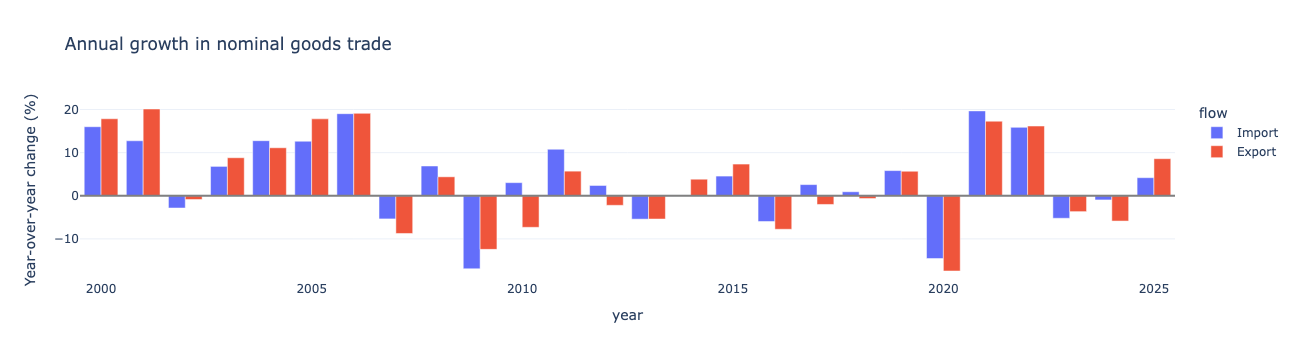

**Largest absolute annual changes (inspect these years):**

,year,flow,growth_pct
3,2001,Export,20.124999
42,2021,Import,19.683587
13,2006,Export,19.116590
12,2006,Import,19.037548
1,2000,Export,17.856654
11,2005,Export,17.841109
41,2020,Export,-17.445581
43,2021,Export,17.296200


In [14]:
if not totals.empty:
    growth = totals[['Import','Export']].pct_change(fill_method=None)*100
    display(growth.round(1).rename(columns={'Import':'Import YoY %','Export':'Export YoY %'}).tail(12))
    g = growth.stack().dropna().reset_index()
    g.columns = ['year','flow','growth_pct']
    if not g.empty:
        fig = px.bar(g, x='year', y='growth_pct', color='flow', barmode='group',
                     title='Annual growth in nominal goods trade',
                     labels={'growth_pct':'Year-over-year change (%)'})
        fig.add_hline(y=0, line_color='gray'); fig.show()
        display(Markdown('**Largest absolute annual changes (inspect these years):**'))
        display(g.assign(abs_change=g.growth_pct.abs()).nlargest(8,'abs_change').drop(columns='abs_change'))

## 7 · Monthly trade: trend and rolling 12-month totals

A monthly dataset is useful for identifying volatility and turning points. Rolling 12-month totals help remove seasonality. Missing months are kept as **missing**, not treated as zero. Do not compare a partial current year with a full previous year as if the periods matched.

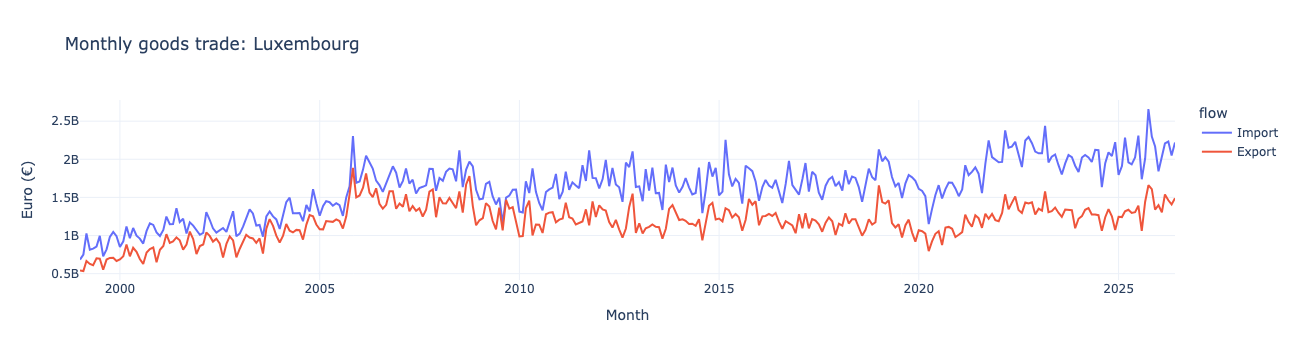

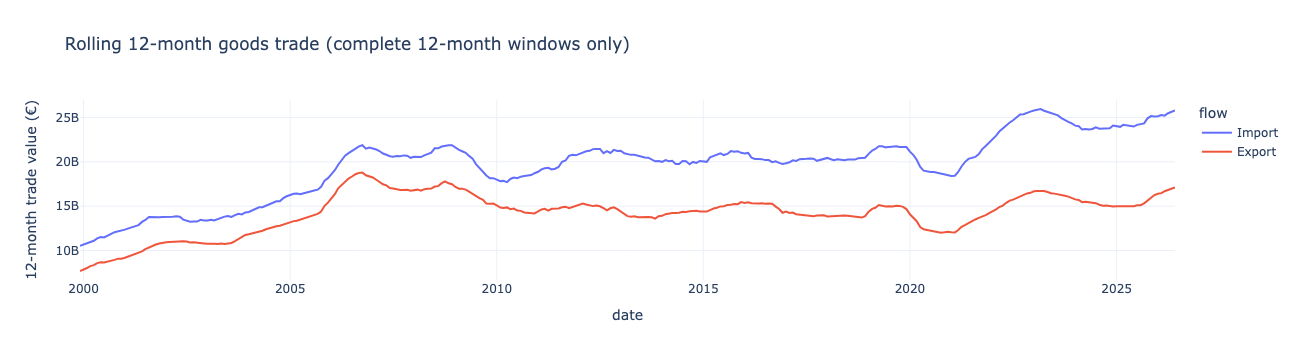

Monthly date range: 1999-01-01 to 2026-06-01


In [15]:
def monthly_flow_pivot(df):
    if df.empty: return pd.DataFrame(columns=['Import','Export'])
    t = (df[df.flow.isin(['Import','Export'])]
         .groupby(['date','flow'])['value'].sum().unstack('flow').sort_index())
    for col in ['Import','Export']:
        if col not in t: t[col] = np.nan
    return t[['Import','Export']].asfreq('MS')

mon = monthly_flow_pivot(monthly_total)
if mon.empty:
    print('No usable monthly euro observations. Skip monthly sections.')
else:
    mon_long = mon.stack().dropna().reset_index()
    mon_long.columns = ['date','flow','eur']
    fig = px.line(mon_long, x='date', y='eur', color='flow',
                  title='Monthly goods trade: Luxembourg', labels={'eur':'Euro (€)','date':'Month'})
    fig.show()
    mon_roll = mon.rolling(window=12, min_periods=12).sum()
    roll_long = mon_roll.stack().dropna().reset_index()
    roll_long.columns = ['date','flow','eur_12mo']
    if not roll_long.empty:
        fig = px.line(roll_long, x='date', y='eur_12mo', color='flow',
                      title='Rolling 12-month goods trade (complete 12-month windows only)',
                      labels={'eur_12mo':'12-month trade value (€)'})
        fig.show()
    print('Monthly date range:', mon.index.min().date(), 'to', mon.index.max().date())

## 8 · Monthly seasonality and year-over-year changes

Average each calendar month **across complete calendar years only**, to avoid distortion from partial years. Seasonal patterns can reflect holidays, inventory cycles, reporting and demand. They are descriptive associations, not proof of causes.

flow,Import months,Export months
year,,
1999,12,12
2000,12,12
2001,12,12
2002,12,12
2003,12,12
2004,12,12
2005,12,12
2006,12,12
2007,12,12


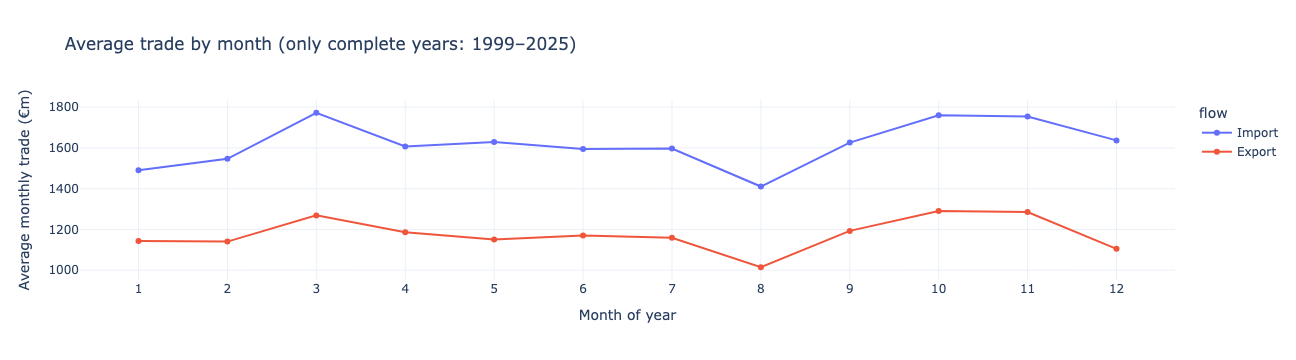

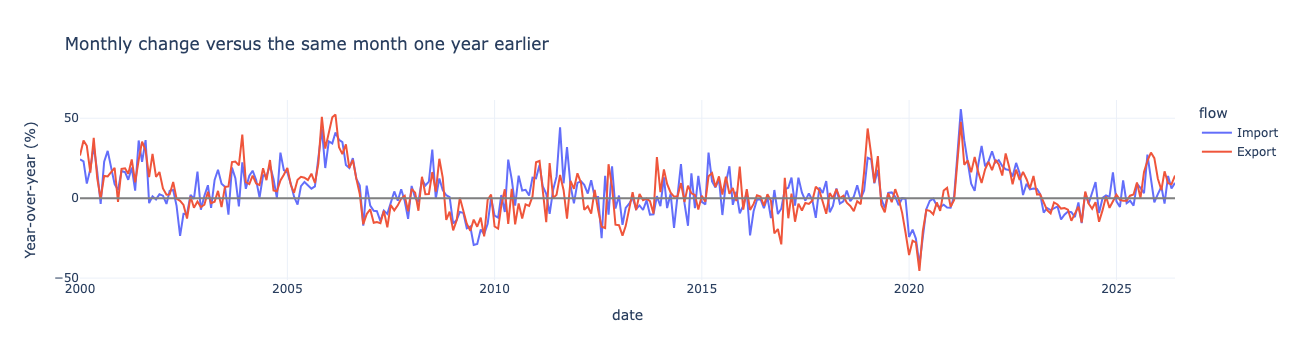

In [16]:
full_years = []
if not mon.empty:
    year_coverage = mon.assign(year=mon.index.year).groupby('year')[['Import','Export']].count()
    display(year_coverage.rename(columns={'Import':'Import months','Export':'Export months'}))
    full_years = year_coverage[(year_coverage[['Import','Export']].min(axis=1)==12)].index.tolist()
    if full_years:
        complete = mon[mon.index.year.isin(full_years)]
        seasonality = complete.groupby(complete.index.month)[['Import','Export']].mean()/1e6
        seaslong = seasonality.reset_index().melt(id_vars='date',var_name='flow',value_name='million_eur')
        fig = px.line(seaslong, x='date', y='million_eur', color='flow', markers=True,
                      title=f'Average trade by month (only complete years: {min(full_years)}–{max(full_years)})',
                      labels={'date':'Month of year','million_eur':'Average monthly trade (€m)'})
        fig.update_xaxes(dtick=1); fig.show()
    else:
        print('No years with all 12 months for both flows. Seasonality chart omitted.')
    mom_yoy = (mon / mon.shift(12) - 1)*100
    yoy_long = mom_yoy.replace([np.inf, -np.inf],np.nan).stack().dropna().reset_index()
    yoy_long.columns = ['date','flow','yoy_pct']
    if not yoy_long.empty:
        fig = px.line(yoy_long, x='date', y='yoy_pct', color='flow',
                      title='Monthly change versus the same month one year earlier',
                      labels={'yoy_pct':'Year-over-year (%)'})
        fig.add_hline(y=0,line_color='gray'); fig.show()

## 9 · Reconcile annual and monthly exports

For a year with all 12 monthly observations, compare the **sum of months** against the reported annual total for the same flow. Eurostat data may be revised; monthly and annual datasets may also contain different selections. A large difference merits inspection, not immediate correction.

flow,Import_annual,Export_annual,Import_monthly,Export_monthly,Import_months,Import_diff_pct,Export_months,Export_diff_pct
year,,,,,,,,
2011,2.073259e+10,1.499014e+10,2.073259e+10,1.499014e+10,12,0.0,12,0.0
2012,2.122822e+10,1.465864e+10,2.122822e+10,1.465864e+10,12,0.0,12,0.0
2013,2.007776e+10,1.386820e+10,2.007776e+10,1.386820e+10,12,0.0,12,0.0
2014,2.009813e+10,1.440096e+10,2.009813e+10,1.440096e+10,12,0.0,12,0.0
2015,2.101614e+10,1.546037e+10,2.101614e+10,1.546037e+10,12,0.0,12,0.0
2016,1.976193e+10,1.425978e+10,1.976193e+10,1.425978e+10,12,0.0,12,0.0
2017,2.027415e+10,1.397290e+10,2.027415e+10,1.397290e+10,12,0.0,12,0.0
2018,2.046300e+10,1.388341e+10,2.046300e+10,1.388341e+10,12,0.0,12,0.0
2019,2.165760e+10,1.467310e+10,2.165760e+10,1.467310e+10,12,0.0,12,0.0


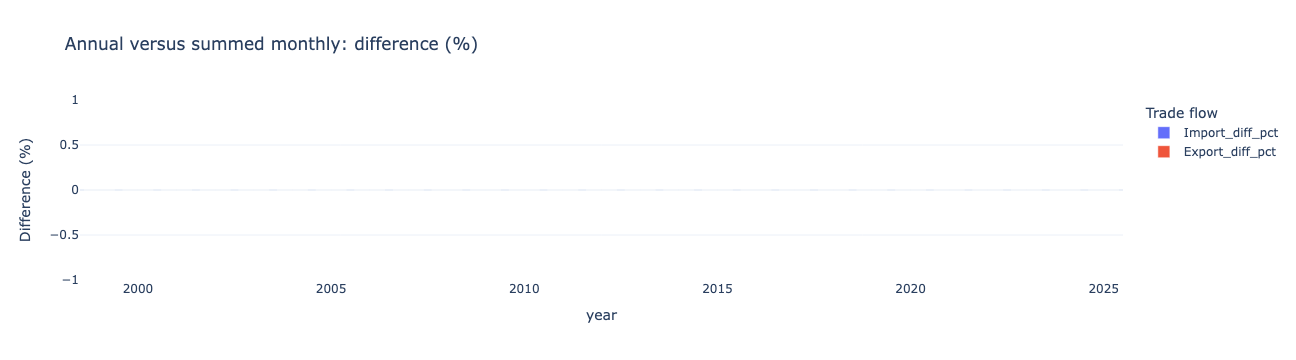

In [17]:
if not totals.empty and not mon.empty:
    m_agg = mon.groupby(mon.index.year).sum(min_count=12)
    m_count = mon.groupby(mon.index.year).count()
    audit = totals[['Import','Export']].join(m_agg, lsuffix='_annual', rsuffix='_monthly', how='inner')
    for flow in ['Import','Export']:
        if flow in m_count:
            audit[f'{flow}_months'] = m_count[flow]
            audit[f'{flow}_diff_pct'] = np.where(
                (audit[f'{flow}_months'] == 12) & audit[f'{flow}_annual'].ne(0),
                (audit[f'{flow}_monthly']/audit[f'{flow}_annual']-1)*100, np.nan)
    display(audit.round(2).tail(15))
    fig_data = audit[[c for c in audit.columns if c.endswith('_diff_pct')]].reset_index()
    if not fig_data.empty:
        fig = px.bar(fig_data, x='year', y=[c for c in fig_data if c.endswith('_diff_pct')],
                     barmode='group', title='Annual versus summed monthly: difference (%)',
                     labels={'value':'Difference (%)','variable':'Trade flow'})
        fig.show()
else:
    print('Annual and monthly euro data are both needed for reconciliation.')

## 10 · Luxembourg's largest import suppliers and export destinations

This section excludes partner totals (`WORLD`, EU aggregates, etc.). Shares are calculated within **the individual partners included in the downloaded selection**. This may not be Luxembourg's full trade if the Eurostat download filters out countries.

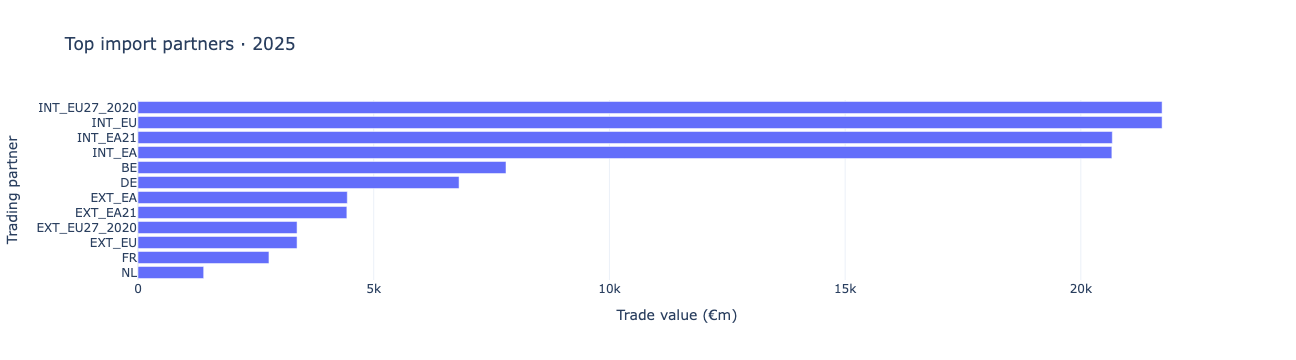

Import — top 5 partners account for 73.8% of the downloaded non-aggregate partner total.


,million_eur
partner,
INT_EU,21723.8
INT_EU27_2020,21723.8
INT_EA21,20667.5
INT_EA,20658.3
BE,7805.9
DE,6810.4
EXT_EA,4439.6
EXT_EA21,4430.4
EXT_EU,3374.2


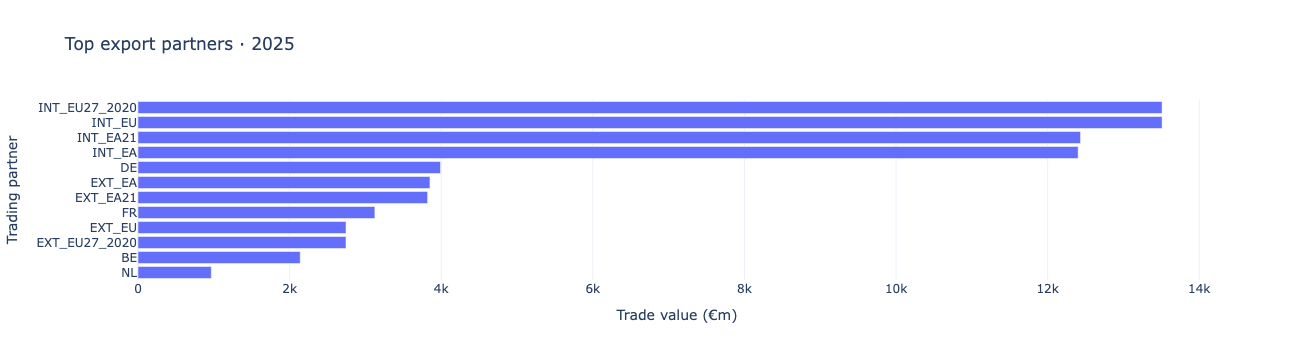

Export — top 5 partners account for 68.7% of the downloaded non-aggregate partner total.


,million_eur
partner,
INT_EU,13509.6
INT_EU27_2020,13509.6
INT_EA21,12433.6
INT_EA,12402.2
DE,3990.7
EXT_EA,3851.6
EXT_EA21,3820.2
FR,3125.0
EXT_EU27_2020,2744.2


In [18]:
if annual_partners.empty:
    print('Partner analysis unavailable: export bilateral partner-country rows.')
else:
    last_partner_year = int(annual_partners.year.max())
    part_latest = annual_partners[annual_partners.year.eq(last_partner_year)]
    for flow in ['Import','Export']:
        ranking = part_latest[part_latest.flow.eq(flow)].groupby('partner')['value'].sum().sort_values(ascending=False)
        if ranking.empty: continue
        top = ranking.head(TOP_N).sort_values()
        chart = px.bar(x=top.values/1e6, y=top.index, orientation='h',
                       title=f'Top {flow.lower()} partners · {last_partner_year}',
                       labels={'x':'Trade value (€m)', 'y':'Trading partner'})
        chart.show()
        print(f'{flow} — top 5 partners account for {100*ranking.head(5).sum()/ranking.sum():.1f}% of the downloaded non-aggregate partner total.')
        display((ranking.head(10)/1e6).round(1).to_frame('million_eur'))

## 11 · Supplier concentration: the HHI indicator

The **Herfindahl–Hirschman index (HHI)** is the sum of squared partner shares. On a 0–10,000 scale, larger values indicate more concentrated trade relationships. This is a **trade concentration proxy**, not a full measure of product availability, geopolitical risk or economic resilience.

,year,flow,hhi,partner_count,top_partner_share
42,2020,Export,1088.06,209,0.16
43,2020,Import,1322.72,185,0.18
44,2021,Export,1090.08,215,0.16
45,2021,Import,1317.09,203,0.18
46,2022,Export,1080.39,210,0.16
47,2022,Import,1369.93,198,0.18
48,2023,Export,1069.21,203,0.16
49,2023,Import,1365.08,194,0.18
50,2024,Export,1090.36,207,0.16
51,2024,Import,1380.85,179,0.18


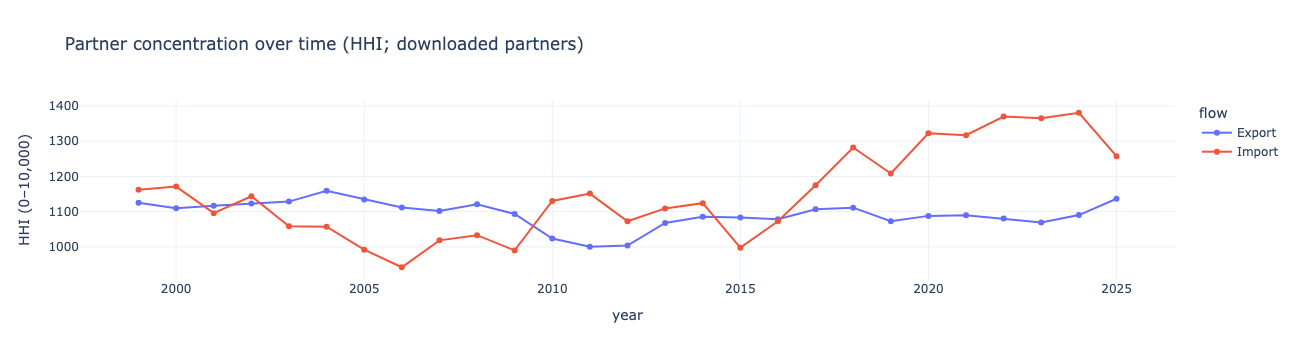

In [19]:
def partner_hhi(data, grouping=['year','flow']):
    d = data.groupby(grouping+['partner'], as_index=False)['value'].sum()
    totals_ = d.groupby(grouping)['value'].transform('sum')
    d = d[totals_.gt(0)].copy()
    d['share'] = d.value / totals_.loc[d.index]
    out = d.assign(sq=d.share**2).groupby(grouping,as_index=False).agg(
        hhi=('sq',lambda s: 10000*s.sum()), partner_count=('partner','nunique'),
        top_partner_share=('share','max'))
    return out

if not annual_partners.empty:
    partner_concentration = partner_hhi(annual_partners)
    display(partner_concentration.tail(12).round(2))
    fig = px.line(partner_concentration, x='year', y='hhi', color='flow', markers=True,
                  title='Partner concentration over time (HHI; downloaded partners)',
                  labels={'hhi':'HHI (0–10,000)'})
    fig.show()

## 12 · Product categories and composition

For a comparable product breakdown, prefer **HS2 chapters**. If only HS4, HS6 or CN8 codes exist, the notebook groups their first two digits. The breakdown is **limited to the selected product categories** in your export, which may be incomplete. Product codes and descriptions can also be revised over time.

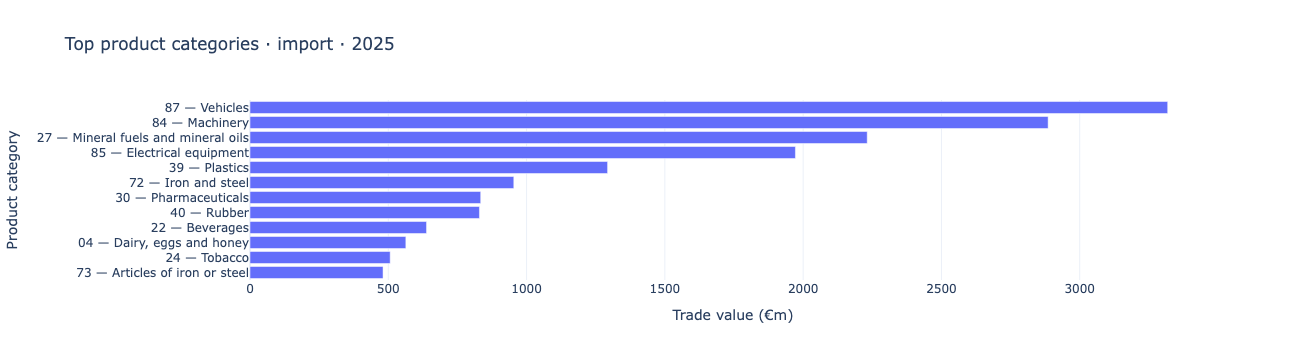

,million_eur
category,
87 — Vehicles,3318.05
84 — Machinery,2885.72
27 — Mineral fuels and mineral oils,2231.64
85 — Electrical equipment,1972.06
39 — Plastics,1292.91
72 — Iron and steel,953.80
30 — Pharmaceuticals,834.16
40 — Rubber,829.62
22 — Beverages,638.28


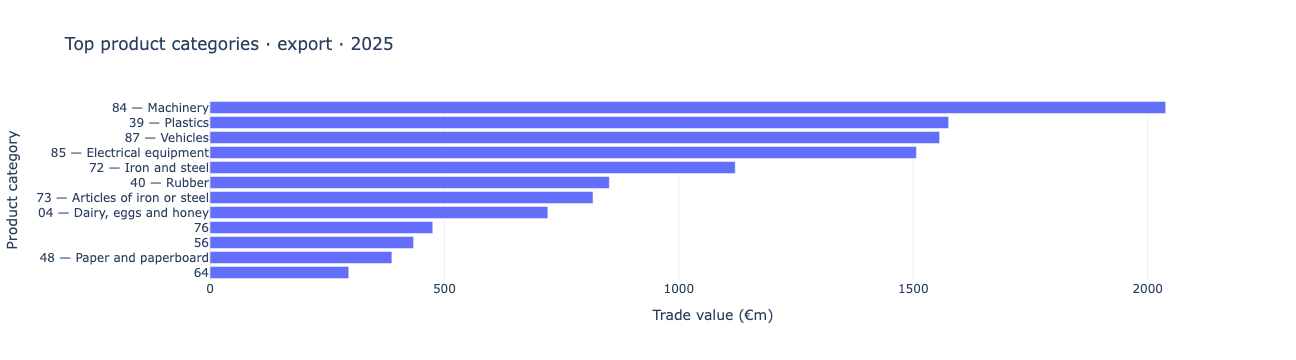

,million_eur
category,
84 — Machinery,2038.49
39 — Plastics,1575.50
87 — Vehicles,1556.32
85 — Electrical equipment,1506.78
72 — Iron and steel,1120.32
40 — Rubber,851.81
73 — Articles of iron or steel,817.02
"04 — Dairy, eggs and honey",720.67
76,475.25


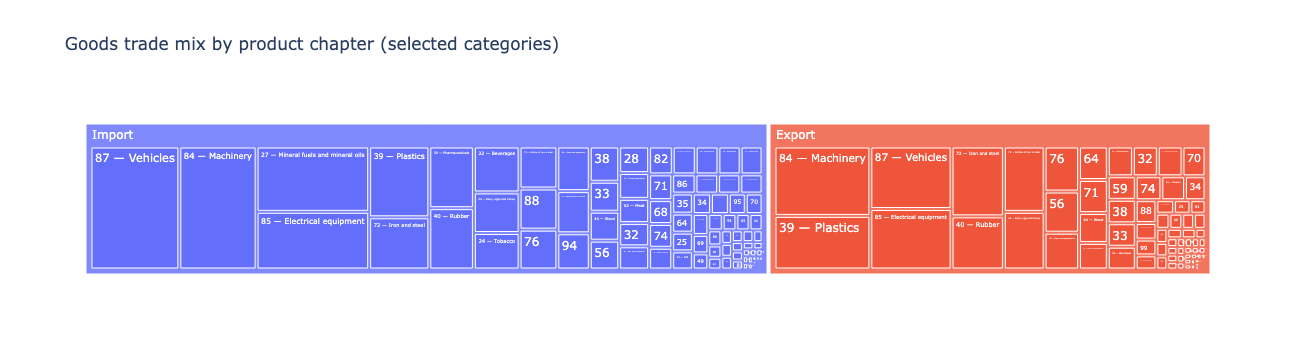

In [20]:
HS2_LABELS = {
    '01':'Live animals','02':'Meat','03':'Fish','04':'Dairy, eggs and honey',
    '05':'Other animal products','06':'Live plants','07':'Vegetables and legumes',
    '08':'Fruit and nuts','09':'Coffee, tea and spices','10':'Cereals',
    '11':'Milling products','12':'Oil seeds and related products','13':'Lacs and gums',
    '14':'Vegetable plaiting materials','15':'Animal/vegetable fats and oils',
    '16':'Prepared meat and fish','17':'Sugar','18':'Cocoa','19':'Cereal preparations',
    '20':'Preparations of vegetables and fruit','21':'Misc. food preparations',
    '22':'Beverages','23':'Food industry residues and animal feed','24':'Tobacco',
    '27':'Mineral fuels and mineral oils','29':'Organic chemicals','30':'Pharmaceuticals',
    '39':'Plastics','40':'Rubber','44':'Wood','48':'Paper and paperboard',
    '61':'Knitted apparel','62':'Other apparel','72':'Iron and steel',
    '73':'Articles of iron or steel','84':'Machinery','85':'Electrical equipment',
    '87':'Vehicles','90':'Optical/medical instruments'
}
def cat_label(v):
    v = str(v)
    return f'{v} — {HS2_LABELS[v]}' if v in HS2_LABELS else v

if annual_products.empty:
    print('No product breakdown exported. Re-export HS2-level observations to analyze products.')
else:
    prod_latest_year = int(annual_products.year.max())
    prod_latest = annual_products[annual_products.year.eq(prod_latest_year)].copy()
    prod_latest['category'] = prod_latest.product_group.map(cat_label)
    for flow in ['Import','Export']:
        ranking = prod_latest[prod_latest.flow.eq(flow)].groupby('category')['value'].sum().sort_values(ascending=False)
        if ranking.empty: continue
        top = ranking.head(TOP_N).sort_values()
        fig = px.bar(x=top.values/1e6, y=top.index, orientation='h',
                     title=f'Top product categories · {flow.lower()} · {prod_latest_year}',
                     labels={'x':'Trade value (€m)','y':'Product category'})
        fig.show()
        display((ranking.head(TOP_N)/1e6).round(2).to_frame('million_eur'))
    p_share = prod_latest.groupby(['flow','category'],as_index=False)['value'].sum()
    if not p_share.empty:
        p_share = p_share[p_share.value>0].copy()
        if not p_share.empty:
            fig = px.treemap(p_share, path=['flow','category'], values='value',
                             title='Goods trade mix by product chapter (selected categories)')
            fig.show()

## 13 · How the product mix has changed

A stacked share chart shows shifts in relative category importance. It avoids confusing rising nominal value with rising market share; however, **price effects remain**.

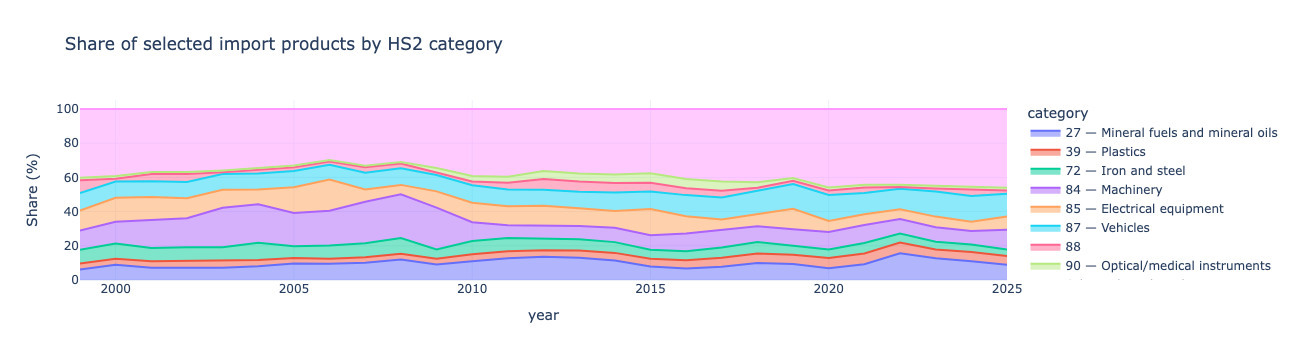

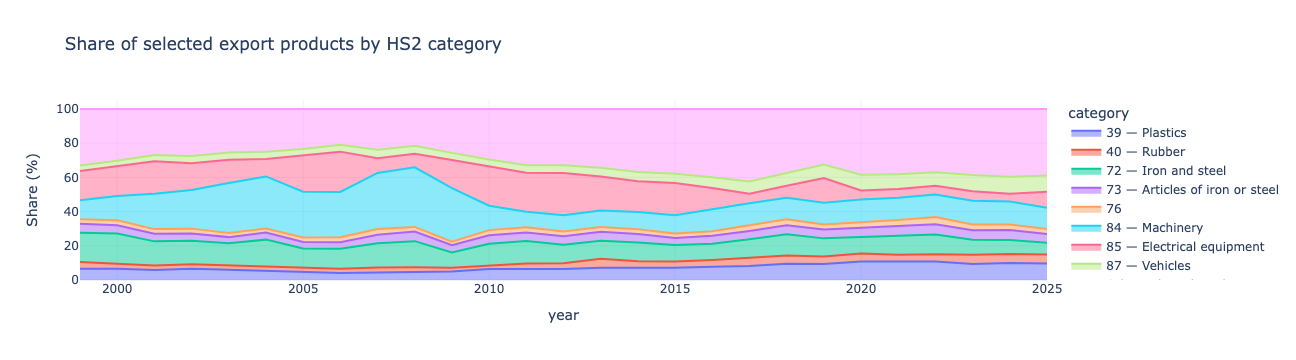

In [21]:
if not annual_products.empty:
    p_history = annual_products.copy()
    p_history['category'] = p_history.product_group.map(cat_label)
    p_history = (p_history.groupby(['year','flow','category'], as_index=False)['value'].sum())
    for flow in ['Import','Export']:
        subset = p_history[p_history.flow.eq(flow)]
        if subset.empty: continue
        largest = subset.groupby('category')['value'].sum().nlargest(8).index
        s = subset.copy()
        s['category'] = np.where(s.category.isin(largest),s.category,'Other selected products')
        s = s.groupby(['year','category'],as_index=False)['value'].sum()
        denom = s.groupby('year').value.transform('sum')
        s['share_pct'] = np.where(denom.ne(0), 100*s.value/denom, np.nan)
        fig = px.area(s, x='year', y='share_pct', color='category',
                      title=f'Share of selected {flow.lower()} products by HS2 category',
                      labels={'share_pct':'Share (%)'})
        fig.show()

## 14 · Product-specific sourcing dependencies

For any category, find its biggest supplier partners. This requires both **detailed products and individual partners** in the download; a `TOTAL × WORLD` table alone cannot answer the question. This is a key input for your Streamlit what-if explorer.

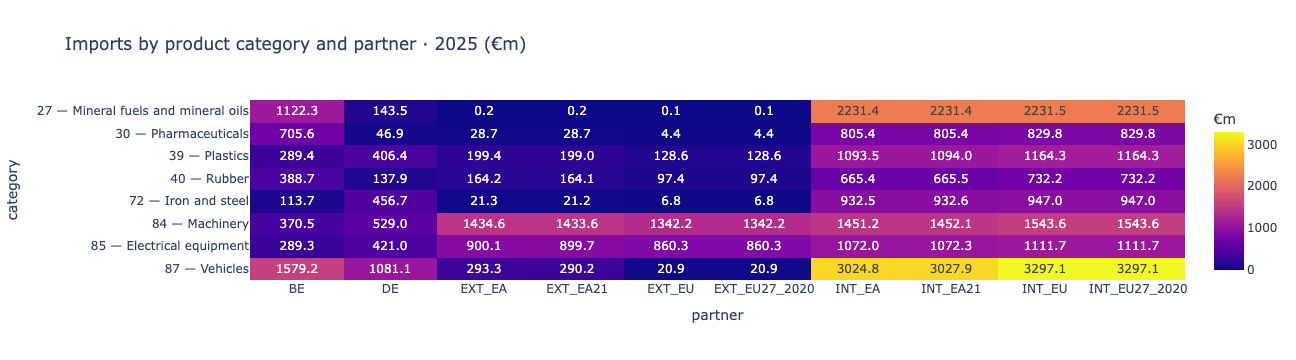

Product/partner scope: HS2 only (selected products may not be exhaustive)


In [22]:
if not annual_eur.empty:
    pp, pp_scope = select_product_grain(annual_eur, require_breakdown=True)
    pp = pp[~pp.is_partner_aggregate].copy()
    if not pp.empty:
        pp['category'] = pp.product_group.map(cat_label)
        last = int(pp.year.max())
        z = pp[(pp.year==last)&(pp.flow=='Import')]
        major = z.groupby('category').value.sum().nlargest(8).index
        heat = (z[z.category.isin(major)]
                .groupby(['category','partner'])['value'].sum().reset_index())
        main_partners = heat.groupby('partner').value.sum().nlargest(10).index
        heat = heat[heat.partner.isin(main_partners)]
        matrix = heat.pivot(index='category',columns='partner',values='value').fillna(0)/1e6
        if not matrix.empty:
            fig = px.imshow(matrix, aspect='auto', text_auto='.1f',
                            title=f'Imports by product category and partner · {last} (€m)',
                            labels={'color':'€m'})
            fig.show()
        print('Product/partner scope:', pp_scope)
    else:
        print('Product-by-partner view unavailable: no disaggregated product × country records.')

## 15 · Net mass and descriptive unit values (where available)

Net mass in **kilograms** supports analysis of physical trade volumes. For narrowly defined goods, `euros / kg` can be a useful descriptive unit value, but it is **not a retail price, delivery quote, profit margin, transport cost, or standardized product price**. Supplementary quantity has product-dependent units and is deliberately excluded here.

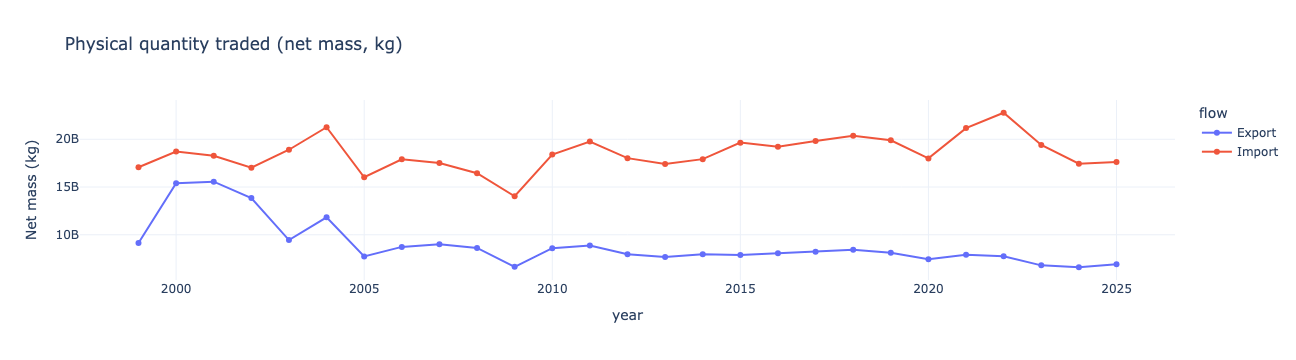

Mass scope: TOTAL product (preferred); World aggregate (preferred)
Comparable product-level value and kg data not both present — unit-value analysis skipped.


In [23]:
annual_mass = mass(annual)
mass_total, mass_scope = trade_scope(annual_mass, 'totals')
if mass_total.empty:
    print('No net mass observations available. Skip kg and € / kg analysis.')
else:
    masses = mass_total[mass_total.flow.isin(['Import','Export'])].groupby(['year','flow'])['value'].sum().reset_index()
    fig = px.line(masses, x='year', y='value', color='flow', markers=True,
                  title='Physical quantity traded (net mass, kg)',labels={'value':'Net mass (kg)'})
    fig.show()
    print('Mass scope:',mass_scope)

# Unit values: restrict to a single fine-grained product level and the same country/year/flow.
unit_keys = ['year','flow','partner','product_code','product_level']
for level in ['CN8','HS6','HS4']:
    v = annual_eur[(annual_eur.product_level==level)&(~annual_eur.is_partner_aggregate)]
    k = annual_mass[(annual_mass.product_level==level)&(~annual_mass.is_partner_aggregate)]
    if len(v) and len(k): break
else:
    v = annual_eur.iloc[:0]; k = annual_mass.iloc[:0]
if len(v) and len(k):
    v1 = v.groupby(unit_keys,as_index=False)['value'].sum().rename(columns={'value':'euros'})
    k1 = k.groupby(unit_keys,as_index=False)['value'].sum().rename(columns={'value':'kg'})
    unit_values = v1.merge(k1,on=unit_keys,how='inner')
    unit_values = unit_values[(unit_values.kg>0)&(unit_values.euros>=0)].copy()
    unit_values['eur_per_kg'] = unit_values.euros/unit_values.kg
    print('Computed narrow-product €/kg on', f'{len(unit_values):,}', 'country/year/product combinations.')
    display(unit_values.sort_values('euros',ascending=False).head(12))
else:
    print('Comparable product-level value and kg data not both present — unit-value analysis skipped.')

## 16 · EDA insights and public-dashboard readiness checklist

**Interpreting the data:** Goods imported by Luxembourg are not necessarily consumed there; re-exports, intra-EU consignment rules and value-chain complexity matter. Also, the supplied dataset does **not directly contain transport modes, kilometres, production emissions, actual sourcing costs, or supplier capacity**.

The following diagnostics summarize what you can support immediately and what would require other datasets.

In [24]:
checks = [
    ('Historical imports and exports',len(annual_total)>0 and annual_total.flow.nunique()==2,
     'Annual euro observations for both flows'),
    ('Monthly seasonality',not mon.empty and len(full_years)>0 if not mon.empty else False,
     '12 months for both flows in at least one year'),
    ('Top bilateral trade partners',len(annual_partners)>0,
     'Non-aggregate partner country observations'),
    ('Product composition',len(annual_products)>0,
     'Non-TOTAL product codes/categories'),
    ('Product-specific supplier exposure',not annual_products.empty and len(annual_eur[~annual_eur.is_partner_aggregate])>0,
     'Product categories × individual partners'),
    ('Trade physical quantities',len(annual_mass)>0,
     'Net mass indicator (kg), not supplementary quantity'),
    ('Transport-emissions estimation',False,
     'Requires route distances, transport modes and emission factors'),
    ('Cost-optimal sourcing simulation',False,
     'Requires comparable landed costs and feasible supplier capacities'),
]
readiness = pd.DataFrame(checks, columns=['Dashboard feature','Available from inspected CSVs?','Minimum basis / additional requirement'])
display(readiness)

print('IMPORTANT CAVEATS')
print('- Nominal euros are not inflation-adjusted trade volumes.')
print('- Partner on intra-EU imports is commonly consignment country, not necessarily origin.')
print('- Export destinations are last known, not necessarily final consumer markets.')
print('- No causal environmental conclusion is possible from monetary flows alone.')

,Dashboard feature,Available from inspected CSVs?,Minimum basis / additional requirement
0,Historical imports and exports,True,Annual euro observations for both flows
1,Monthly seasonality,True,12 months for both flows in at least one year
2,Top bilateral trade partners,True,Non-aggregate partner country observations
3,Product composition,True,Non-TOTAL product codes/categories
4,Product-specific supplier exposure,True,Product categories × individual partners
5,Trade physical quantities,True,"Net mass indicator (kg), not supplementary quantity"
6,Transport-emissions estimation,False,"Requires route distances, transport modes and emission factors"
7,Cost-optimal sourcing simulation,False,Requires comparable landed costs and feasible supplier capacities


IMPORTANT CAVEATS
- Nominal euros are not inflation-adjusted trade volumes.
- Partner on intra-EU imports is commonly consignment country, not necessarily origin.
- Export destinations are last known, not necessarily final consumer markets.
- No causal environmental conclusion is possible from monetary flows alone.


## 17 · Automatically generated findings for your dashboard

These observations are generated from your selected data, with explicit scope caveats. They are preliminary descriptive insights, not causal explanations. The section also saves a Markdown summary for your Streamlit storytelling.

In [25]:
insights = ['# Preliminary EDA insights: Luxembourg goods trade', '',
            f'- **Annual-total scope:** {annual_scope}',
            f'- **Partner scope:** {partner_scope}',
            f'- **Product scope:** {product_scope}', '']
if not totals.empty:
    last_y = int(totals.index.max())
    for label in ['Import','Export','Balance']:
        v = totals.loc[last_y, label]
        if pd.notna(v):
            insights.append(f'- **{last_y} {label.lower()} value:** €{v/1e9:,.3f} billion.')
if not annual_partners.empty:
    last_y = int(annual_partners.year.max())
    for flow in ['Import','Export']:
        g = (annual_partners[(annual_partners.year==last_y)&(annual_partners.flow==flow)]
             .groupby('partner').value.sum().sort_values(ascending=False))
        if len(g) and g.sum()>0:
            insights.append(f'- **Largest {flow.lower()} partner ({last_y}):** {g.index[0]} '
                            f'({g.iloc[0]/g.sum()*100:.1f}% of downloaded country-partner values).')
if not annual_products.empty:
    last_y = int(annual_products.year.max())
    g = (annual_products[(annual_products.year==last_y)&(annual_products.flow=='Import')]
         .groupby('product_group').value.sum().sort_values(ascending=False))
    if len(g) and g.sum()>0:
        insights.append(f'- **Largest import category ({last_y}):** {cat_label(g.index[0])} '
                        f'({g.iloc[0]/g.sum()*100:.1f}% of selected product categories).')
insights += ['', '## Methodological cautions',
             '- Describes international trade in **goods**, not trade in services.',
             '- No direct environmental impact can be calculated from monetary trade value alone.',
             '- Unselected products/partners in a custom export can materially change shares and totals.',
             '- Eurostat series are subject to revision.']
summary_text = '\n'.join(insights)
display(Markdown(summary_text))
(OUTPUT_DIR/'eda_executive_summary.md').write_text(summary_text, encoding='utf-8')

# Preliminary EDA insights: Luxembourg goods trade

- **Annual-total scope:** TOTAL product (preferred); World aggregate (preferred)
- **Partner scope:** TOTAL product (preferred); Individual countries/partners only
- **Product scope:** HS2 only (selected products may not be exhaustive); World aggregate (preferred)

- **2025 import value:** €25.098 billion.
- **2025 export value:** €16.254 billion.
- **2025 balance value:** €-8.844 billion.
- **Largest import partner (2025):** INT_EU (17.3% of downloaded country-partner values).
- **Largest export partner (2025):** INT_EU (16.6% of downloaded country-partner values).
- **Largest import category (2025):** 87 — Vehicles (13.2% of selected product categories).

## Methodological cautions
- Describes international trade in **goods**, not trade in services.
- No direct environmental impact can be calculated from monetary trade value alone.
- Unselected products/partners in a custom export can materially change shares and totals.
- Eurostat series are subject to revision.

1031

## 18 · Export clean data for Streamlit

Write canonical observations and pre-aggregated tables. This saves time when building the dashboard. If files are too large, narrow the input in Eurostat to `REPORTER=LU`, reasonable year ranges, and the product granularity you need. The metadata file records aggregation scope.

In [26]:
import json
trade.to_csv(OUTPUT_DIR/'luxembourg_trade_clean.csv', index=False)
if not totals.empty:
    totals.reset_index().to_csv(OUTPUT_DIR/'annual_trade_totals.csv', index=False)
if not mon.empty:
    mon.reset_index().to_csv(OUTPUT_DIR/'monthly_trade_totals.csv', index=False)
if not annual_partners.empty:
    annual_partners.groupby(['year','flow','partner'],as_index=False)['value'].sum().to_csv(
        OUTPUT_DIR/'annual_trade_by_partner.csv',index=False)
if not annual_products.empty:
    annual_products.groupby(['year','flow','product_group'],as_index=False)['value'].sum().to_csv(
        OUTPUT_DIR/'annual_trade_by_product.csv', index=False)
if 'partner_concentration' in globals() and not partner_concentration.empty:
    partner_concentration.to_csv(OUTPUT_DIR/'annual_partner_concentration.csv',index=False)

metadata = {
    'source': 'Eurostat DS-045409', 'reporter': 'Luxembourg',
    'source_files': [p.name for p in files], 'annual_scope':annual_scope,
    'monthly_scope':monthly_scope, 'partner_scope':partner_scope,
    'product_scope':product_scope,
    'note': 'Only describe these as Luxembourg total goods trade if TOTAL × WORLD and full coverage verified.'
}
(OUTPUT_DIR/'analysis_metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
print('Exported files:')
for p in sorted(OUTPUT_DIR.iterdir()):
    if p.is_file(): print(' -',p,'(',f'{p.stat().st_size/1024:.1f} KB',')')

Exported files:
 - outputs/analysis_metadata.json ( 0.6 KB )
 - outputs/annual_partner_concentration.csv ( 2.9 KB )
 - outputs/annual_trade_by_partner.csv ( 238.9 KB )
 - outputs/annual_trade_by_product.csv ( 131.8 KB )
 - outputs/annual_trade_totals.csv ( 1.6 KB )
 - outputs/eda_executive_summary.md ( 1.0 KB )
 - outputs/luxembourg_trade_clean.csv ( 491122.0 KB )
 - outputs/monthly_trade_totals.csv ( 11.9 KB )


## 19 · What to take into the two-day Streamlit dashboard

| Story chapter | Best available visual | Suggested data file | Key interpretation |
|---|---|---|---|
| **1. Where do we stand?** | Imports vs exports line chart + balance KPI | `annual_trade_totals.csv` | Value trends; always label total vs subset |
| **1. Where do we trade?** | Top partner bars / map | `annual_trade_by_partner.csv` | Concentration of Luxembourg's trade |
| **2. What are the impacts?** | Supplier concentration + product heatmap | `annual_partner_concentration.csv` | Dependencies; **not** estimated CO₂ without supplemental sources |
| **3. What if we changed?** | Change top supplier's share via slider | `annual_trade_by_partner.csv` | Illustrative diversification, not a feasible optimization result |
| **4. What does the future hold?** | Historical line + transparent hypothetical scenario ranges | `annual_trade_totals.csv` | Clearly distinguish assumptions from forecasts |

### Optional: environmental impact extension

If you have net mass by product and partner, you can **later** estimate transport CO₂e using *tonnes × route kilometres × mode-specific emission factor*. But DS-045409 alone does **not** provide the mode or exact route. Do **not** equate trade monetary value with emissions.

### Sources / methodology
- [Eurostat DS-045409](https://ec.europa.eu/eurostat/databrowser/view/ds-045409/default/table)
- [Eurostat: international trade in goods — detailed data metadata](https://ec.europa.eu/eurostat/cache/metadata/en/ext_go_detail_sims.htm)
- [Eurostat: international trade in goods database](https://ec.europa.eu/eurostat/web/international-trade-in-goods/database)

**Next step:** Review the audit and scope warnings produced by this notebook before drafting any public-facing claims about Luxembourg's trade totals.